<a href="https://colab.research.google.com/github/OscarGalloGarcia/Msc-DeepLearning-course/blob/main/L05_Red_Neuronal_Densa_TF_LoanPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa en TensorFlow
## Dr. Carlos Villaseñor


### Alumno: Oscar Alberto Gallo García
Msc Ciencias en Robótica e Inteligencia Artificial


A05 Redes Densas con TensorFlow

Dataset: "loan_prediction.csv" cuya variable de interés es "Loan_Status"

Paso 1. Correr paqueterias

In [ ]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importamos Tensorflow y Keras
import tensorflow as tf
from tensorflow import keras

# Usamos funcionalidades básicas de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# tensor flow version y GPU de colab
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))
print(tf.config.experimental.get_device_details(tf.config.list_physical_devices('GPU')[0]))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'compute_capability': (7, 5), 'device_name': 'Tesla T4'}


Paso 2. Carga el archivo, y la lectura con pandas

In [ ]:
!wget 'https://github.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/raw/main/Datasets/Housing.csv'

--2026-10-12 04:49:58--  https://github.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/raw/main/Datasets/Housing.csv
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/main/Datasets/Housing.csv [following]
--2026-10-12 04:49:58--  https://raw.githubusercontent.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/main/Datasets/Housing.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 29981 (29K) [text/plain]
Saving to: ‘Housing.csv.3’

Housing.csv.3       100%[===================>]  29.28K  --.-KB/s    in 0.004s  

2026-10-12 04:49:58 (7.79 MB/s)

In [ ]:
dataset = pd.read_csv('Housing.csv')
dataset.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Paso 3. Limpieza de los datos

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [ ]:
# Como tenemos varias columnas con texto debemos aplicar One-hot encoding
# Columna furnishingstatus
origin = dataset.pop('furnishingstatus')
dataset['furnished'] = (origin == 'furnished')*1.0
dataset['semi-furnished'] = (origin == 'semi-furnished')*1.0
dataset['unfurnished'] = (origin == 'unfurnished')*1.0
dataset.tail()

#columnas mainroad	guestroom	basement	hotwaterheating	airconditioning
# Son texto yes/no debemos convertirlo a 0 / 1 numerico
origin = dataset.pop('mainroad')
dataset['mainroad'] = (origin == 'yes')*1.0
origin = dataset.pop('guestroom')
dataset['guestroom'] = (origin == 'yes')*1.0
origin = dataset.pop('basement')
dataset['basement'] = (origin == 'yes')*1.0
origin = dataset.pop('hotwaterheating')
dataset['hotwaterheating'] = (origin == 'yes')*1.0
origin = dataset.pop('airconditioning')
dataset['airconditioning'] = (origin == 'yes')*1.0
origin = dataset.pop('prefarea')
dataset['prefarea'] = (origin == 'yes')*1.0
dataset.tail()

dataset.head()

,price,area,bedrooms,bathrooms,stories,parking,furnished,semi-furnished,unfurnished,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea
0,13300000,7420,4,2,3,2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
1,12250000,8960,4,4,4,3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,12250000,9960,3,2,2,2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
3,12215000,7500,4,2,2,3,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
4,11410000,7420,4,1,2,2,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0


In [ ]:
np.array(dataset.price)

array([13300000, 12250000, 12250000, 12215000, 11410000, 10850000,
       10150000, 10150000,  9870000,  9800000,  9800000,  9681000,
        9310000,  9240000,  9240000,  9100000,  9100000,  8960000,
        8890000,  8855000,  8750000,  8680000,  8645000,  8645000,
        8575000,  8540000,  8463000,  8400000,  8400000,  8400000,
        8400000,  8400000,  8295000,  8190000,  8120000,  8080940,
        8043000,  7980000,  7962500,  7910000,  7875000,  7840000,
        7700000,  7700000,  7560000,  7560000,  7525000,  7490000,
        7455000,  7420000,  7420000,  7420000,  7350000,  7350000,
        7350000,  7350000,  7343000,  7245000,  7210000,  7210000,
        7140000,  7070000,  7070000,  7035000,  7000000,  6930000,
        6930000,  6895000,  6860000,  6790000,  6790000,  6755000,
        6720000,  6685000,  6650000,  6650000,  6650000,  6650000,
        6650000,  6650000,  6629000,  6615000,  6615000,  6580000,
        6510000,  6510000,  6510000,  6475000,  6475000,  6440

Paso 3. Revisar datos faltantes

In [ ]:
dataset.isna().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
parking,0
furnished,0
semi-furnished,0
unfurnished,0
mainroad,0


Paso 7. Elige las variables de entrada y salida

In [ ]:
x = np.asanyarray(dataset.drop(columns=['price']))
y = np.asanyarray(dataset[['price']])
x = StandardScaler().fit_transform(x)
y = StandardScaler().fit_transform(y)
print(x.shape)
print(y.shape)

(545, 14)
(545, 1)


Paso 8. Particiona el dataset

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2)

In [ ]:
#Para este experimento como los datos vienen como int64 pero los necesitamos como float32

xtrain = xtrain.astype('float32')
xtest = xtest.astype('float32')
ytrain = ytrain.astype('float32')
ytest = ytest.astype('float32')



Paso 9. Crea una red neuronal para aprender los datos.

In [ ]:
from keras import ops
from keras import backend as K

def r2score(y_true, y_pred):
    SS_res = ops.sum(ops.square(y_true - y_pred))
    SS_tot = ops.sum(ops.square(y_true - ops.mean(y_true)))
    return 1 - SS_res / (SS_tot + K.epsilon())

In [ ]:
# Es un problema de regresion por lo tanto en la neurona de salida usaremos

def build_model():

  model = keras.Sequential()
  model.add(keras.layers.Dense(128, activation='relu', input_shape=[x.shape[1]]))
  model.add(keras.layers.Dropout(0.2))
  model.add(keras.layers.Dense(32, activation='tanh'))
  #Capa de salida con la funcion linear
  #Se pone esto en la salida porque es un problema de regresion
  model.add(keras.layers.Dense(1, activation='linear'))

  #En la funcion de costo se usa MSE
  # En metricas se usa R2SCORE
  model.compile(loss='mean_squared_error',
                optimizer=keras.optimizers.Adam(),
                metrics=[keras.metrics.MAE, r2score])
  return  model

In [ ]:
model = build_model()
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,081 (23.75 KB)

 Trainable params: 6,081 (23.75 KB)

 Non-trainable params: 0 (0.00 B)

Paso 10. Entrena la red neuronal

In [ ]:
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest), verbose=0)

Paso 11. Dibuja las curvas de aprendizaje para un mejor diagnóstico del aprendizaje

In [ ]:
def plot_history(history):
  hist = pd.DataFrame(history.history)
  print(hist.columns)

Index(['loss', 'mean_absolute_error', 'r2score', 'val_loss',
       'val_mean_absolute_error', 'val_r2score'],
      dtype='object')


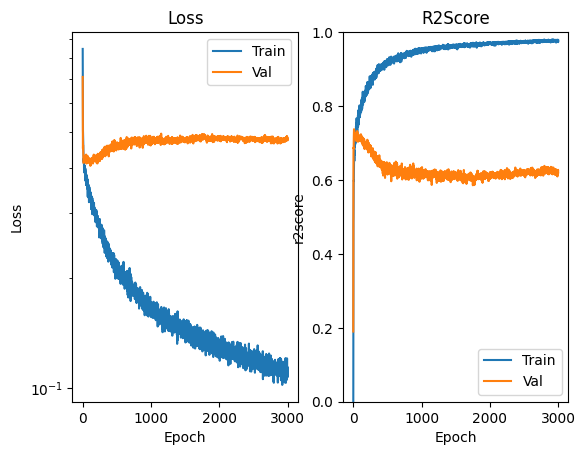

In [ ]:
def plot_history(history):
  hist = pd.DataFrame(history.history)
  print(hist.columns)
  hist['epoch'] = history.epoch
  plt.figure()
  plt.subplot(121)
  plt.title('Loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['mean_absolute_error'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_mean_absolute_error'],
           label = 'Val')
  plt.yscale('log')
  plt.legend()

  plt.subplot(122)
  plt.title('R2Score')
  plt.xlabel('Epoch')
  plt.ylabel('r2score')
  plt.plot(hist['epoch'], hist['r2score'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_r2score'],
           label = 'Val')
  plt.ylim([0,1])
  plt.legend()

plot_history(history)

Paso 12. Implementación de Eary Stopping como regulador

In [ ]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=20)
model = build_model()
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest),
                    verbose=1, callbacks=[es])

Epoch 1/3000


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 634ms/step - loss: 1.1169 - mean_absolute_error: 0.8255 - r2score: -0.1763 - val_loss: 0.9337 - val_mean_absolute_error: 0.7834 - val_r2score: 0.1105
Epoch 2/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.7764 - mean_absolute_error: 0.6793 - r2score: 0.2076 - val_loss: 0.6345 - val_mean_absolute_error: 0.6151 - val_r2score: 0.3956
Epoch 3/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.5717 - mean_absolute_error: 0.5700 - r2score: 0.4242 - val_loss: 0.4687 - val_mean_absolute_error: 0.5275 - val_r2score: 0.5534
Epoch 4/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.4916 - mean_absolute_error: 0.5208 - r2score: 0.5013 - val_loss: 0.3944 - val_mean_absolute_error: 0.5007 - val_r2score: 0.6242
Epoch 5/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.4706 - mean_absolute_error: 0.5182 - r2score: 0.5207 - val_loss: 0.3792 - val_mean_absolute_error: 0.4974 - val_r2score: 0.6388
Epoch 6/3000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.3935 

Index(['loss', 'mean_absolute_error', 'r2score', 'val_loss',
       'val_mean_absolute_error', 'val_r2score'],
      dtype='object')


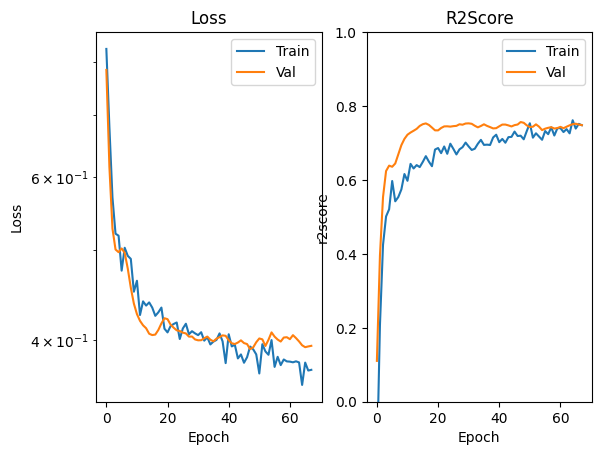

In [ ]:
plot_history(history)

In [ ]:
# Descargar en HTML con el nombre exacto detectado en tu sesión
!jupyter nbconvert --to html "Copia_de_L05_Red_Neuronal_Densa_TF_Housing (1)"

[NbConvertApp] Converting notebook Copia_de_L05_Red_Neuronal_Densa_TF_Housing (1).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 458305 bytes to Copia_de_L05_Red_Neuronal_Densa_TF_Housing (1).html
